In [ ]:
%matplotlib inline

In [ ]:
%env SIT_ROOT=/sdf/group/lcls/ds/ana
%env SIT_PSDM_DATA=/sdf/data/lcls/ds
%env CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
%env SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/

env: SIT_ROOT=/sdf/group/lcls/ds/ana
env: SIT_PSDM_DATA=/sdf/data/lcls/ds
env: CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
env: SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/


## Imports

In [ ]:
import numpy as np
import sys
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import socket
import pyFAI as pf
from pyFAI.gui import jupyter
from pyFAI.gui.jupyter.calib import Calibration

from tqdm import tqdm

import sys
from pathlib import Path

import ana_fun as ana

from utilities import *

print(f"PyFAI version {pf.version}")


Smalldata path exists: True
Jungfrau path exists: True
epix2 path exists: True
iq path exists: True
PyFAI version 0.21.3


## ePix 5 SAXS - Contrast Analysis

In [ ]:
def circle(radius,radius2, xcenter,ycenter, shape):
    c=np.zeros([shape[0],shape[1],])
    for x in range(shape[0]):
        for y in range(shape[1]):
            if (((x-xcenter)**2+(y-ycenter)**2)<radius**2)&(((x-xcenter)**2+(y-ycenter)**2)>radius2**2):
                c[x,y]=1
    return c

mask = epix5_mask.astype(bool)
roi = circle(radius=220,radius2=150, xcenter=353,ycenter=350, shape=(mask.shape))
shape = mask.shape
nframe = 40003

mask_total = ((~epix5_mask.astype(bool))*roi.astype(bool)).T
print(mask_total)

# Create arrays for the result
kbar_per_epix = np.zeros(nframe)
beta_per_epix = np.zeros(nframe)
delays = np.zeros(nframe)

# temp probability arrays
p0_per_epix = np.zeros(nframe)
p1_per_epix = np.zeros(nframe)
p2_per_epix = np.zeros(nframe)
p3_per_epix = np.zeros(nframe)

# plt.imshow(epix5_img.mean(0)*mask_total)
# plt.show()

with h5py.File(f) as h5:
    for frame in tqdm(range(40003)):
        delays[frame] = h5[f'delay_ps'][frame]
        epix5_img = h5[f'img'][frame]
        img = epix5_img * mask_total
        # intensity
        kbar_per_epix[frame] = np.nanmean(epix5_img)
        beta_per_epix[frame] = np.var(epix5_img.flatten())/(kbar_per_epix[frame])**2

np.save(Path(shared, "output", "kbar_epix5_run119.npy"), kbar_per_epix)
np.save(Path(shared, "output", "contrast_epix5_run119.npy"), beta_per_epix)

    # beta_per_epix[frame] = (2 * p2_per_epix[frame] - kbar_per_epix[frame] * p1_per_epix[frame]) / (kbar_per_epix[frame] * (p1_per_epix[frame] - 2 * p2_per_epix[frame]))

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


  4%|▍         | 1684/40003 [00:10<04:05, 155.85it/s]


KeyboardInterrupt: 

In [ ]:
# np.save(Path(shared, "output", "kbar_epix5_run119.npy") kbar_per_epix))
kbar = np.load(Path(shared, "output", "kbar_epix5_run119.npy"))
contrast = np.load(Path(shared, "output", "contrast_epix5_run119.npy"))

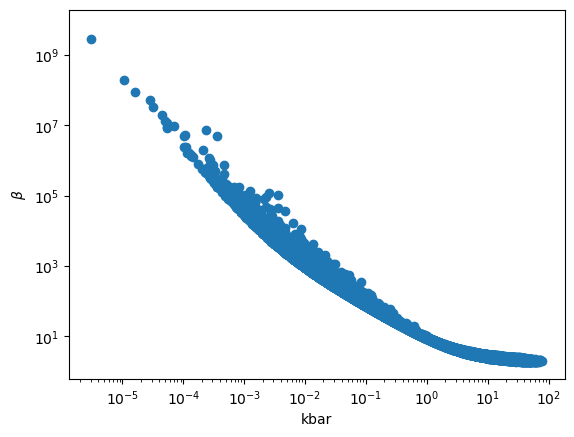

In [ ]:
plt.scatter(kbar, contrast)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("kbar")
plt.ylabel(r"$\beta$")
plt.show()

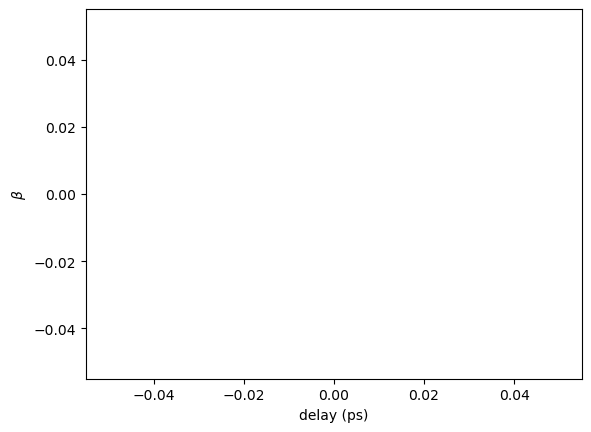

In [ ]:
plt.scatter(delays[np.where(kbar > 100)], contrast[np.where(kbar > 100)])
plt.xlabel("delay (ps)")
plt.ylabel(r"$\beta$")
plt.show()

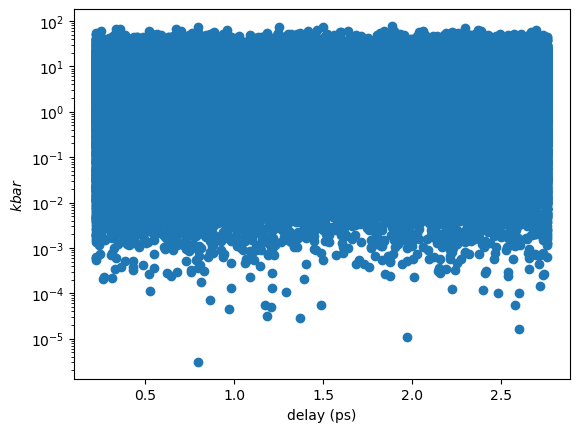

In [ ]:
plt.scatter(delays, kbar)
plt.xlabel("delay (ps)")
plt.ylabel(r"$kbar$")
plt.yscale("log")
plt.show()


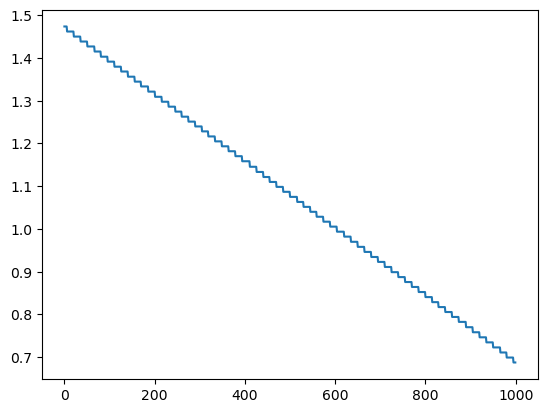

In [ ]:
plt.plot(delays)